# 01 — Persiapan Data
**Temu Kembali Citra X-Ray Dada Berbasis Konten untuk Pendukung Diagnosis Pneumonia Bakteri dan Virus pada Anak**

Langkah pada notebook ini:
1. Membaca dataset X-ray dada anak Kermany dkk. dan memberi label 3 kelas dari nama file.
2. Mendeteksi dan menghapus citra yang identik (duplikat).
3. Membagi data **per pasien** (70% latih, 15% validasi, 15% uji) agar tidak terjadi kebocoran data.
4. Menampilkan contoh citra dan efek CLAHE.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

PROJECT = Path.cwd().parent                      # folder "Tugas Temu Kembali Citra"
RAW_DIR = PROJECT / "data pneumonia" / "chest_xray"
DATA_DIR = PROJECT / "data"                      # split dan cache citra hasil persiapan data
OUTPUTS = PROJECT / "outputs"                    # model dan hasil eksperimen
HASIL = Path("hasil")                            # keluaran notebook (terpisah dari outputs/)
HASIL.mkdir(exist_ok=True)
CLASSES = ["Normal", "Bacteria", "Virus"]
NAMA_KELAS = {"Normal": "Normal", "Bacteria": "Pneumonia Bakteri", "Virus": "Pneumonia Virus"}
print("Folder project:", PROJECT)

Folder project: C:\Users\LENOVO\Documents\Temu Kembali Citra\Tugas\Tugas Temu Kembali Citra


In [2]:
import hashlib, re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold

## 1. Pelabelan 3 kelas dan identitas pasien dari nama file
Folder asli hanya berisi `NORMAL` dan `PNEUMONIA`. Jenis pneumonia dan nomor pasien tertulis di nama file, misalnya
`person23_bacteria_105.jpeg` (pasien 23, bakteri) atau `IM-0115-0001.jpeg` (normal, pasien IM-0115).

In [3]:
def parse_name(path):
    """Mengembalikan (label, id_pasien) dari nama file."""
    if path.parent.name == "NORMAL":
        m = re.match(r"((?:NORMAL2-)?IM-\d+)-", path.name)
        return "Normal", "N_" + m.group(1)
    m = re.match(r"person(\d+)_(bacteria|virus)_", path.name)
    # Nomor pasien yang sama muncul pada file bakteri dan virus -> disatukan dalam satu grup (aman dari kebocoran).
    return m.group(2).capitalize(), "P_" + m.group(1)

rows = []
for path in sorted(RAW_DIR.glob("*/*/*.jpeg")):
    label, patient = parse_name(path)
    rows.append({"raw_path": str(path.relative_to(PROJECT)), "orig_split": path.parts[-3], "label": label,
                 "patient": patient, "md5": hashlib.md5(path.read_bytes()).hexdigest()})
df = pd.DataFrame(rows)
print("Jumlah citra:", len(df))
df["label"].value_counts().rename(NAMA_KELAS).to_frame("jumlah citra")

Jumlah citra: 5856


,jumlah citra
label,
Pneumonia Bakteri,2780
Normal,1583
Pneumonia Virus,1493


## 2. Deteksi citra duplikat (hash MD5 identik)

In [4]:
dup = df[df.duplicated("md5", keep=False)].sort_values("md5")
print("Citra yang memiliki kembaran identik:", len(dup), "| akan dihapus:", df.duplicated("md5").sum())
display(dup[["raw_path", "label", "patient"]].head(6))
df = df.drop_duplicates("md5", keep="first").reset_index(drop=True)
print("Sisa citra unik:", len(df), "| jumlah kelompok pasien:", df["patient"].nunique())

Citra yang memiliki kembaran identik: 62 | akan dihapus: 32


,raw_path,label,patient
138,data pneumonia\chest_xray\test\NORMAL\NORMAL2-...,Normal,N_NORMAL2-IM-0246
139,data pneumonia\chest_xray\test\NORMAL\NORMAL2-...,Normal,N_NORMAL2-IM-0246
3297,data pneumonia\chest_xray\train\PNEUMONIA\pers...,Bacteria,P_1619
3298,data pneumonia\chest_xray\train\PNEUMONIA\pers...,Bacteria,P_1619
2692,data pneumonia\chest_xray\train\PNEUMONIA\pers...,Bacteria,P_1349
2693,data pneumonia\chest_xray\train\PNEUMONIA\pers...,Bacteria,P_1349


Sisa citra unik: 5824 | jumlah kelompok pasien: 3117


## 3. Pembagian data per pasien
`StratifiedGroupKFold` membagi data menjadi 20 fold dengan proporsi kelas terjaga dan satu pasien hanya berada di
satu fold. Fold 0–2 menjadi data uji, 3–5 data validasi, dan sisanya data latih.

In [5]:
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=42)
fold = pd.Series(-1, index=df.index)
for k, (_, idx) in enumerate(sgkf.split(df, df["label"], groups=df["patient"])):
    fold.iloc[idx] = k
df["split"] = fold.map(lambda k: "test" if k < 3 else "val" if k < 6 else "train")

bocor = df.groupby("patient")["split"].nunique().max() > 1
print("Ada pasien di lebih dari satu bagian?", bocor)
ringkas = pd.crosstab(df["split"], df["label"])[CLASSES].loc[["train", "val", "test"]]
ringkas["Total"] = ringkas.sum(axis=1)
ringkas["Pasien"] = df.groupby("split")["patient"].nunique()
ringkas

Ada pasien di lebih dari satu bagian? False


label,Normal,Bacteria,Virus,Total,Pasien
split,,,,,
train,1101,1909,1020,4030,2173
val,243,426,210,879,471
test,235,425,255,915,473


In [6]:
# Pembagian ini identik dengan yang dipakai pada eksperimen (data/splits.csv).
df["cache_name"] = df["orig_split"] + "_" + df["raw_path"].map(lambda p: Path(p).stem) + ".png"
eksperimen = pd.read_csv(DATA_DIR / "splits.csv")
sama = df[["cache_name", "label", "split"]].reset_index(drop=True).equals(
    eksperimen[["cache_name", "label", "split"]].reset_index(drop=True))
print("Sama dengan split eksperimen:", sama)
df.drop(columns="md5").to_csv(HASIL / "splits_notebook.csv", index=False)

Sama dengan split eksperimen: True


## 4. Contoh citra setiap kelas dan distribusi data

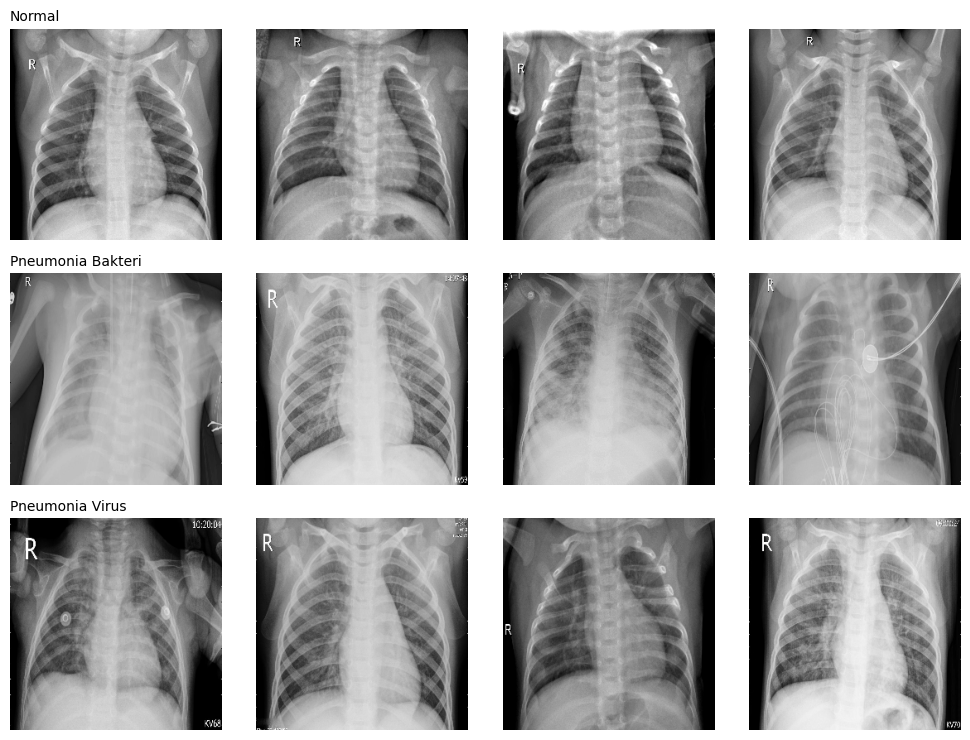

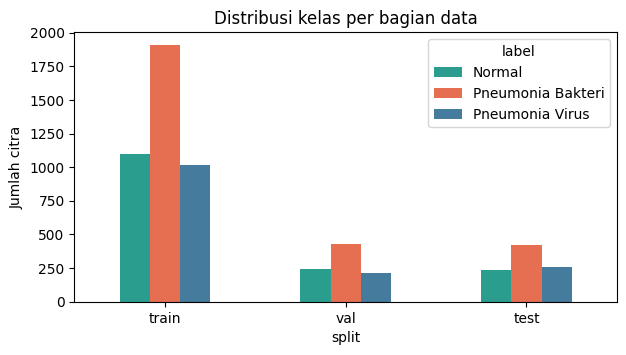

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(10, 7.5))
for r, cls in enumerate(CLASSES):
    for c, p in enumerate(df[df["label"] == cls].sample(4, random_state=7)["raw_path"]):
        img = cv2.imread(str(PROJECT / p), cv2.IMREAD_GRAYSCALE)
        axes[r, c].imshow(cv2.resize(img, (256, 256)), cmap="gray"); axes[r, c].axis("off")
    axes[r, 0].set_title(NAMA_KELAS[cls], loc="left", fontsize=10)
plt.tight_layout(); plt.show()

ringkas[CLASSES].rename(columns=NAMA_KELAS).plot(kind="bar", rot=0, figsize=(7, 3.5),
                                                 color=["#2a9d8f", "#e76f51", "#457b9d"])
plt.ylabel("Jumlah citra"); plt.title("Distribusi kelas per bagian data"); plt.show()

## 5. Praproses dan CLAHE (Skenario 3)
Citra diubah ke grayscale dan 256×256 piksel. CLAHE (clip limit 2,0; tile 8×8) memperjelas kontras lokal jaringan paru.

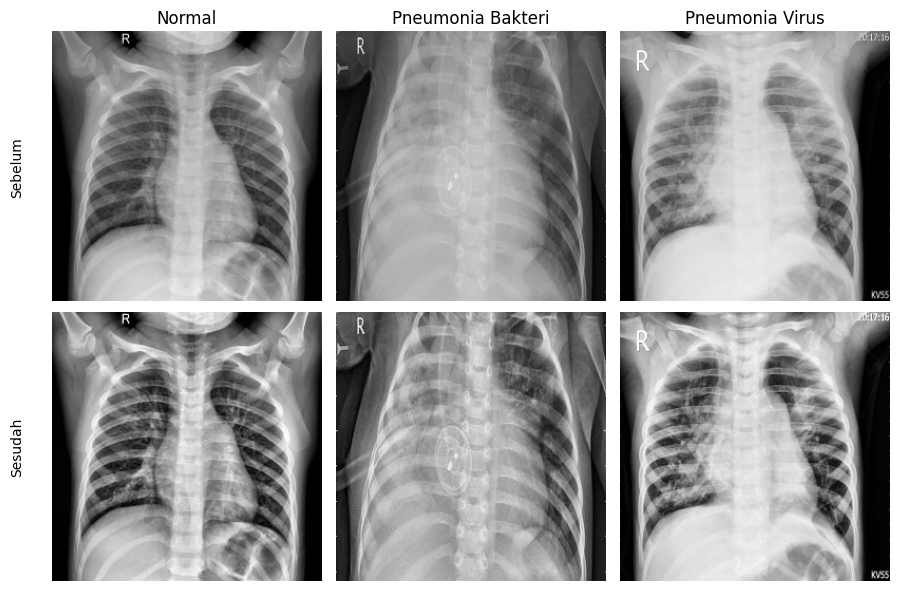

In [8]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for c, cls in enumerate(CLASSES):
    p = df[df["label"] == cls].sample(1, random_state=3)["raw_path"].iloc[0]
    img = cv2.resize(cv2.imread(str(PROJECT / p), cv2.IMREAD_GRAYSCALE), (256, 256), interpolation=cv2.INTER_AREA)
    axes[0, c].imshow(img, cmap="gray"); axes[0, c].set_title(NAMA_KELAS[cls])
    axes[1, c].imshow(clahe.apply(img), cmap="gray")
    for r in range(2): axes[r, c].axis("off")
axes[0, 0].text(-40, 128, "Sebelum", rotation=90, va="center"); axes[1, 0].text(-40, 128, "Sesudah", rotation=90, va="center")
plt.tight_layout(); plt.show()